# CSCI323 Group Project Code
## Sentiment Analysis on IMDb Movie Reviews

This notebook runs our IMDb sentiment analysis experiments for the group project.

Plan:
- Tier 1: Naive Bayes baseline and feature tests
- Tier 2: compare LinearSVC and Logistic Regression
- Tier 3: try SBERT embeddings

Dataset: `stanfordnlp/imdb` from Hugging Face.

In [1]:
# Step 1: setup
# Run this first in Colab.
!pip -q install datasets sentence-transformers nltk

import os
import re
import time
import html
import warnings
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, classification_report
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Use quick mode only for testing.
# For final results keep QUICK_MODE = False.
QUICK_MODE = False

# SBERT is slower, so it has its own switch.
RUN_TIER3 = True

# Optional slow model, not needed for final run.
# We keep this off by default.
RUN_SLOW_TFIDF_RBF_SVC = False

# Lemmatization is available but kept off.
USE_LEMMATIZATION = False

OUTPUT_DIR = "/content/csci323_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Setup done.")
print("Output folder:", OUTPUT_DIR)

Setup done.
Output folder: /content/csci323_outputs


## Baseline Reference

The baseline idea came from the GitHub repo listed in our report. This notebook does not clone the repo during running, because we only need our own final experiment code here.

In [2]:
# Step 2: load data

# IMDb already has train and test splits.
# Split train into train + validation.
# train: 20,000, validation: 5,000, test: 25,000
# Validation is used for tuning.
# Test is only for final results.

dataset = load_dataset("stanfordnlp/imdb")

train_full = dataset["train"].to_pandas()[["text", "label"]]
test_df = dataset["test"].to_pandas()[["text", "label"]]

train_df, val_df = train_test_split(
    train_full,
    test_size=0.2,
    stratify=train_full["label"],
    random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

def stratified_sample(df, n, random_state=RANDOM_STATE):
    # Smaller sample for quick testing.
    if n >= len(df):
        return df.sample(frac=1, random_state=random_state).reset_index(drop=True)
    per_class = n // 2
    part0 = df[df["label"] == 0].sample(per_class, random_state=random_state)
    part1 = df[df["label"] == 1].sample(per_class, random_state=random_state)
    return pd.concat([part0, part1]).sample(frac=1, random_state=random_state).reset_index(drop=True)

if QUICK_MODE:
    train_df = stratified_sample(train_df, 4000)
    val_df = stratified_sample(val_df, 1000)
    test_df = stratified_sample(test_df, 4000)

label_names = {0: "negative", 1: "positive"}

print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))
print()
print("Train label distribution:")
print(train_df["label"].value_counts().sort_index())
print()
print("Test label distribution:")
print(test_df["label"].value_counts().sort_index())

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Train size: 20000
Validation size: 5000
Test size: 25000

Train label distribution:
label
0    10000
1    10000
Name: count, dtype: int64

Test label distribution:
label
0    12500
1    12500
Name: count, dtype: int64


In [3]:
# Step 3: dataset summary

def average_word_count(texts):
    return np.mean([len(str(t).split()) for t in texts])

summary_rows = []
for split_name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    counts = df["label"].value_counts().sort_index()
    summary_rows.append({
        "split": split_name,
        "num_reviews": len(df),
        "negative_count": int(counts.get(0, 0)),
        "positive_count": int(counts.get(1, 0)),
        "avg_words_per_review": round(average_word_count(df["text"]), 2)
    })

dataset_summary = pd.DataFrame(summary_rows)
dataset_summary.to_csv(os.path.join(OUTPUT_DIR, "dataset_summary.csv"), index=False)

display(dataset_summary)
print("Saved:", os.path.join(OUTPUT_DIR, "dataset_summary.csv"))

,split,num_reviews,negative_count,positive_count,avg_words_per_review
0,train,20000,10000,10000,233.14
1,validation,5000,2500,2500,236.38
2,test,25000,12500,12500,228.53


Saved: /content/csci323_outputs/dataset_summary.csv


In [4]:
# Step 4: text cleaning

# Basic cleaning for the review text.

if USE_LEMMATIZATION:
    import nltk
    nltk.download("wordnet")
    nltk.download("omw-1.4")
    from nltk.stem import WordNetLemmatizer
    lemmatizer = WordNetLemmatizer()
else:
    lemmatizer = None

NEGATION_WORDS = {
    "no", "not", "nor", "never", "cannot",
    "can't", "don't", "doesn't", "didn't",
    "isn't", "wasn't", "weren't",
    "won't", "wouldn't", "shouldn't", "couldn't"
}

STOP_WORDS_FOR_SENTIMENT = set(ENGLISH_STOP_WORDS) - NEGATION_WORDS

def clean_text(text, remove_stopwords=False, do_lemmatize=False):
    text = str(text)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)       # remove HTML like <br />
    text = text.lower()
    text = re.sub(r"[^a-zA-Z']", " ", text)    # keep letters and apostrophes
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()

    if remove_stopwords:
        tokens = [w for w in tokens if w not in STOP_WORDS_FOR_SENTIMENT]

    if do_lemmatize and lemmatizer is not None:
        tokens = [lemmatizer.lemmatize(w) for w in tokens]

    return " ".join(tokens)

def build_text_versions():
    # Make the text versions once.
    versions = {}

    versions["raw"] = {
        "train": train_df["text"].tolist(),
        "val": val_df["text"].tolist(),
        "test": test_df["text"].tolist()
    }

    versions["clean"] = {
        "train": [clean_text(t, remove_stopwords=False, do_lemmatize=USE_LEMMATIZATION) for t in train_df["text"]],
        "val": [clean_text(t, remove_stopwords=False, do_lemmatize=USE_LEMMATIZATION) for t in val_df["text"]],
        "test": [clean_text(t, remove_stopwords=False, do_lemmatize=USE_LEMMATIZATION) for t in test_df["text"]]
    }

    versions["clean_stop"] = {
        "train": [clean_text(t, remove_stopwords=True, do_lemmatize=USE_LEMMATIZATION) for t in train_df["text"]],
        "val": [clean_text(t, remove_stopwords=True, do_lemmatize=USE_LEMMATIZATION) for t in val_df["text"]],
        "test": [clean_text(t, remove_stopwords=True, do_lemmatize=USE_LEMMATIZATION) for t in test_df["text"]]
    }

    return versions

start = time.time()
text_versions = build_text_versions()
print("Text versions created in", round(time.time() - start, 2), "seconds")
print("Example cleaned text:")
print(text_versions["clean"]["train"][0][:500])

Text versions created in 32.36 seconds
Example cleaned text:
i have always been a huge james bond fanatic i have seen almost all of the films except for die another day and the world is not enough the graphic's for everything or nothing are breathtaking the voice talents wow i love pierce brosnan he is finally bond in a video game he is bond i enjoyed the past bond games goldeneye the world is not enough agent under fire and nightfire this one is definitely the best finally mr brosnan may i call him mr brosnan as a sign of respect yes i can he was phenome


In [5]:
# Step 5: helper functions

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

results = []
saved_models = {}

def get_positive_score(model, X):
    # Score for the positive class.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    return None

def calc_metrics(y_true, y_pred, y_score=None):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0
    )
    acc = accuracy_score(y_true, y_pred)

    auc = np.nan
    if y_score is not None:
        try:
            auc = roc_auc_score(y_true, y_score)
        except Exception:
            auc = np.nan

    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auc": auc
    }

def make_vectorizer(kind="count", ngram_range=(1, 1), max_features=50000):
    if kind == "count":
        return CountVectorizer(ngram_range=ngram_range, max_features=max_features)
    elif kind == "tfidf":
        return TfidfVectorizer(ngram_range=ngram_range, max_features=max_features)
    else:
        raise ValueError("kind must be 'count' or 'tfidf'")

def run_text_experiment(
    exp_id,
    tier,
    goal,
    text_key,
    vectorizer_kind,
    classifier,
    classifier_name,
    ngram_range=(1, 1),
    max_features=50000
):
    # Train and evaluate one experiment.
    X_train_text = text_versions[text_key]["train"]
    X_val_text = text_versions[text_key]["val"]
    X_test_text = text_versions[text_key]["test"]

    vectorizer = make_vectorizer(vectorizer_kind, ngram_range, max_features)

    pipe = Pipeline([
        ("vectorizer", vectorizer),
        ("model", classifier)
    ])

    start_time = time.time()
    pipe.fit(X_train_text, y_train)
    train_time = time.time() - start_time

    val_pred = pipe.predict(X_val_text)
    test_pred = pipe.predict(X_test_text)

    val_score = get_positive_score(pipe, X_val_text)
    test_score = get_positive_score(pipe, X_test_text)

    val_metrics = calc_metrics(y_val, val_pred, val_score)
    test_metrics = calc_metrics(y_test, test_pred, test_score)

    row = {
        "exp_id": exp_id,
        "tier": tier,
        "goal": goal,
        "text_version": text_key,
        "feature": vectorizer_kind,
        "ngram": str(ngram_range),
        "classifier": classifier_name,
        "train_size_used": int(len(y_train)),
        "feature_time_sec": 0.0,
        "train_time_sec": round(train_time, 3),
        "notes": "",

        "val_accuracy": round(val_metrics["accuracy"], 4),
        "val_precision": round(val_metrics["precision"], 4),
        "val_recall": round(val_metrics["recall"], 4),
        "val_f1": round(val_metrics["f1"], 4),
        "val_auc": round(val_metrics["auc"], 4) if not np.isnan(val_metrics["auc"]) else np.nan,

        "test_accuracy": round(test_metrics["accuracy"], 4),
        "test_precision": round(test_metrics["precision"], 4),
        "test_recall": round(test_metrics["recall"], 4),
        "test_f1": round(test_metrics["f1"], 4),
        "test_auc": round(test_metrics["auc"], 4) if not np.isnan(test_metrics["auc"]) else np.nan
    }

    results.append(row)

    saved_models[exp_id] = {
        "model": pipe,
        "feature_type": "text",
        "X_test": X_test_text,
        "y_test": y_test,
        "test_pred": test_pred,
        "test_score": test_score,
        "row": row
    }

    print(exp_id, classifier_name, "done. Test F1 =", row["test_f1"], "AUC =", row["test_auc"])
    return row

In [6]:
# Step 6: experiment list

experiment_design = pd.DataFrame([
    ["1.1", "Tier 1", "Baseline: raw text + CountVectorizer + MultinomialNB", "Raw text", "Count unigram", "MultinomialNB"],
    ["1.2", "Tier 1", "Test basic preprocessing", "Clean text", "Count unigram", "MultinomialNB"],
    ["1.3", "Tier 1", "Test stopword removal", "Clean text without stopwords", "Count unigram", "MultinomialNB"],
    ["1.4", "Tier 1", "Tune Naive Bayes alpha", "Clean text", "Count unigram", "MultinomialNB with tuned alpha"],
    ["1.5", "Tier 1", "Compare Count with TF-IDF", "Clean text", "TF-IDF unigram", "MultinomialNB"],
    ["1.6", "Tier 1", "Test unigram + bigram", "Clean text", "TF-IDF unigram + bigram", "MultinomialNB"],
    ["2.1", "Tier 2", "Compare LinearSVC", "Best Tier 1 text setting", "Best Tier 1 feature setting", "LinearSVC"],
    ["2.2", "Tier 2", "Compare Logistic Regression", "Best Tier 1 text setting", "Best Tier 1 feature setting", "LogisticRegression"],
    ["3.1", "Tier 3", "Use SBERT sentence embeddings", "HTML-cleaned natural text", "SBERT all-MiniLM-L6-v2", "LogisticRegression"],
    ["3.2", "Tier 3", "Use SBERT with non-linear SVC", "HTML-cleaned natural text", "SBERT all-MiniLM-L6-v2", "SVC RBF"],
], columns=["experiment_id", "tier", "aim", "text_input", "feature", "classifier"])

experiment_design.to_csv(os.path.join(OUTPUT_DIR, "experiment_design.csv"), index=False)
display(experiment_design)
print("Saved:", os.path.join(OUTPUT_DIR, "experiment_design.csv"))

,experiment_id,tier,aim,text_input,feature,classifier
0,1.1,Tier 1,Baseline: raw text + CountVectorizer + Multino...,Raw text,Count unigram,MultinomialNB
1,1.2,Tier 1,Test basic preprocessing,Clean text,Count unigram,MultinomialNB
2,1.3,Tier 1,Test stopword removal,Clean text without stopwords,Count unigram,MultinomialNB
3,1.4,Tier 1,Tune Naive Bayes alpha,Clean text,Count unigram,MultinomialNB with tuned alpha
4,1.5,Tier 1,Compare Count with TF-IDF,Clean text,TF-IDF unigram,MultinomialNB
5,1.6,Tier 1,Test unigram + bigram,Clean text,TF-IDF unigram + bigram,MultinomialNB
6,2.1,Tier 2,Compare LinearSVC,Best Tier 1 text setting,Best Tier 1 feature setting,LinearSVC
7,2.2,Tier 2,Compare Logistic Regression,Best Tier 1 text setting,Best Tier 1 feature setting,LogisticRegression
8,3.1,Tier 3,Use SBERT sentence embeddings,HTML-cleaned natural text,SBERT all-MiniLM-L6-v2,LogisticRegression
9,3.2,Tier 3,Use SBERT with non-linear SVC,HTML-cleaned natural text,SBERT all-MiniLM-L6-v2,SVC RBF


Saved: /content/csci323_outputs/experiment_design.csv


1.1 MultinomialNB(alpha=1.0) done. Test F1 = 0.799 AUC = 0.8911
1.2 MultinomialNB(alpha=1.0) done. Test F1 = 0.8009 AUC = 0.8916
1.3 MultinomialNB(alpha=1.0) done. Test F1 = 0.8083 AUC = 0.8938
Alpha tuning results:


,alpha,val_accuracy,val_precision,val_recall,val_f1,val_auc,train_time_sec
0,0.01,0.8410,0.866352,0.8064,0.835301,0.910967,3.094560
1,0.10,0.8454,0.869807,0.8124,0.840124,0.915332,3.837475
2,0.50,0.8486,0.876783,0.8112,0.842718,0.916940,2.922810
3,1.00,0.8470,0.876683,0.8076,0.840725,0.917066,3.074868
4,2.00,0.8446,0.872782,0.8068,0.838495,0.916620,3.009247
5,5.00,0.8416,0.870660,0.8024,0.835137,0.915220,3.018178


Best alpha based on validation F1: 0.5


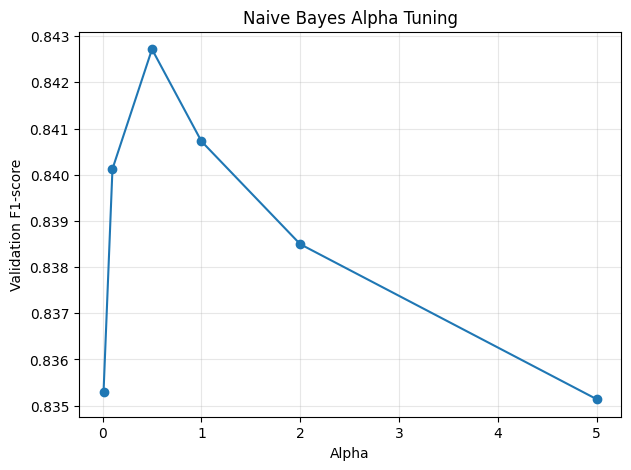

1.4 MultinomialNB(alpha=0.5) done. Test F1 = 0.7987 AUC = 0.8892
1.5 MultinomialNB(alpha=0.5) done. Test F1 = 0.8176 AUC = 0.9113
1.6 MultinomialNB(alpha=0.5) done. Test F1 = 0.8649 AUC = 0.9422


,exp_id,tier,goal,text_version,feature,ngram,classifier,train_size_used,feature_time_sec,train_time_sec,...,val_accuracy,val_precision,val_recall,val_f1,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,1.1,Tier 1,Baseline: raw text + CountVectorizer + Multino...,raw,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.0,4.197,...,0.8452,0.8746,0.8060,0.8389,0.9164,0.8123,0.8599,0.7462,0.7990,0.8911
1,1.2,Tier 1,Basic preprocessing impact,clean,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.0,3.970,...,0.8470,0.8767,0.8076,0.8407,0.9171,0.8137,0.8601,0.7494,0.8009,0.8916
2,1.3,Tier 1,Stopword removal impact,clean_stop,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.0,2.474,...,0.8498,0.8729,0.8188,0.8450,0.9221,0.8195,0.8618,0.7610,0.8083,0.8938
3,1.4,Tier 1,Alpha tuning with best alpha = 0.5,clean,count,"(1, 1)",MultinomialNB(alpha=0.5),20000,0.0,3.919,...,0.8486,0.8768,0.8112,0.8427,0.9169,0.8116,0.8575,0.7474,0.7987,0.8892
4,1.5,Tier 1,TF-IDF unigram feature,clean,tfidf,"(1, 1)",MultinomialNB(alpha=0.5),20000,0.0,4.204,...,0.8612,0.8797,0.8368,0.8577,0.9361,0.8276,0.8680,0.7727,0.8176,0.9113
5,1.6,Tier 1,TF-IDF unigram + bigram feature,clean,tfidf,"(1, 2)",MultinomialNB(alpha=0.5),20000,0.0,11.840,...,0.8774,0.8853,0.8672,0.8761,0.9516,0.8680,0.8857,0.8451,0.8649,0.9422


In [7]:
# Step 7: Tier 1 - Naive Bayes
# Tier 1 keeps NB as the classifier.
# Change one setting at a time.

# 1.1 baseline: raw text + CountVectorizer + MultinomialNB
run_text_experiment(
    exp_id="1.1",
    tier="Tier 1",
    goal="Baseline: raw text + CountVectorizer + MultinomialNB",
    text_key="raw",
    vectorizer_kind="count",
    classifier=MultinomialNB(alpha=1.0),
    classifier_name="MultinomialNB(alpha=1.0)",
    ngram_range=(1, 1)
)

# 1.2 preprocessing
run_text_experiment(
    exp_id="1.2",
    tier="Tier 1",
    goal="Basic preprocessing impact",
    text_key="clean",
    vectorizer_kind="count",
    classifier=MultinomialNB(alpha=1.0),
    classifier_name="MultinomialNB(alpha=1.0)",
    ngram_range=(1, 1)
)

# 1.3 stopword removal
run_text_experiment(
    exp_id="1.3",
    tier="Tier 1",
    goal="Stopword removal impact",
    text_key="clean_stop",
    vectorizer_kind="count",
    classifier=MultinomialNB(alpha=1.0),
    classifier_name="MultinomialNB(alpha=1.0)",
    ngram_range=(1, 1)
)

# 1.4 alpha tuning on validation set
alpha_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0]
alpha_rows = []

# Tune alpha on the validation set.
for alpha in alpha_values:
    vectorizer = CountVectorizer(ngram_range=(1, 1), max_features=50000)
    model = Pipeline([
        ("vectorizer", vectorizer),
        ("model", MultinomialNB(alpha=alpha))
    ])

    start_time = time.time()
    model.fit(text_versions["clean"]["train"], y_train)
    train_time = time.time() - start_time

    val_pred = model.predict(text_versions["clean"]["val"])
    val_score = get_positive_score(model, text_versions["clean"]["val"])
    val_metrics = calc_metrics(y_val, val_pred, val_score)

    alpha_rows.append({
        "alpha": alpha,
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_auc": val_metrics["auc"],
        "train_time_sec": train_time
    })

alpha_df = pd.DataFrame(alpha_rows)
best_alpha = float(alpha_df.sort_values("val_f1", ascending=False).iloc[0]["alpha"])
alpha_df.to_csv(os.path.join(OUTPUT_DIR, "alpha_tuning_results.csv"), index=False)

print("Alpha tuning results:")
display(alpha_df)
print("Best alpha based on validation F1:", best_alpha)

plt.figure(figsize=(7, 5))
plt.plot(alpha_df["alpha"], alpha_df["val_f1"], marker="o")
plt.xlabel("Alpha")
plt.ylabel("Validation F1-score")
plt.title("Naive Bayes Alpha Tuning")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, "alpha_tuning_curve.png"), dpi=200, bbox_inches="tight")
plt.show()

# Run the best alpha setting.
run_text_experiment(
    exp_id="1.4",
    tier="Tier 1",
    goal=f"Alpha tuning with best alpha = {best_alpha}",
    text_key="clean",
    vectorizer_kind="count",
    classifier=MultinomialNB(alpha=best_alpha),
    classifier_name=f"MultinomialNB(alpha={best_alpha})",
    ngram_range=(1, 1)
)

# 1.5 TF-IDF unigram
run_text_experiment(
    exp_id="1.5",
    tier="Tier 1",
    goal="TF-IDF unigram feature",
    text_key="clean",
    vectorizer_kind="tfidf",
    classifier=MultinomialNB(alpha=best_alpha),
    classifier_name=f"MultinomialNB(alpha={best_alpha})",
    ngram_range=(1, 1)
)

# 1.6 TF-IDF unigram + bigram
run_text_experiment(
    exp_id="1.6",
    tier="Tier 1",
    goal="TF-IDF unigram + bigram feature",
    text_key="clean",
    vectorizer_kind="tfidf",
    classifier=MultinomialNB(alpha=best_alpha),
    classifier_name=f"MultinomialNB(alpha={best_alpha})",
    ngram_range=(1, 2),
    max_features=80000
)

tier1_results = pd.DataFrame(results)
display(tier1_results[tier1_results["tier"] == "Tier 1"])

In [8]:
# Step 8: choose best Tier 1 setup
# Pick using validation F1.

result_df = pd.DataFrame(results)
tier1_df = result_df[result_df["tier"] == "Tier 1"].copy()

best_tier1_row = tier1_df.sort_values("val_f1", ascending=False).iloc[0]
best_tier1_id = best_tier1_row["exp_id"]

best_text_key = best_tier1_row["text_version"]
best_feature_kind = best_tier1_row["feature"]
best_ngram = ast.literal_eval(best_tier1_row["ngram"])

print("Best Tier 1 experiment based on validation F1:")
display(best_tier1_row.to_frame().T)
print("Best text version:", best_text_key)
print("Best feature:", best_feature_kind)
print("Best ngram:", best_ngram)

Best Tier 1 experiment based on validation F1:


,exp_id,tier,goal,text_version,feature,ngram,classifier,train_size_used,feature_time_sec,train_time_sec,...,val_accuracy,val_precision,val_recall,val_f1,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
5,1.6,Tier 1,TF-IDF unigram + bigram feature,clean,tfidf,"(1, 2)",MultinomialNB(alpha=0.5),20000,0.0,11.84,...,0.8774,0.8853,0.8672,0.8761,0.9516,0.868,0.8857,0.8451,0.8649,0.9422


Best text version: clean
Best feature: tfidf
Best ngram: (1, 2)


In [9]:
# Step 9: Tier 2 - other classifiers
# Use the best Tier 1 features.
# Now only change the classifier.

# 2.1 LinearSVC
run_text_experiment(
    exp_id="2.1",
    tier="Tier 2",
    goal="Best Tier 1 feature + LinearSVC",
    text_key=best_text_key,
    vectorizer_kind=best_feature_kind,
    classifier=LinearSVC(random_state=RANDOM_STATE, max_iter=5000),
    classifier_name="LinearSVC",
    ngram_range=best_ngram,
    max_features=80000 if best_ngram == (1, 2) else 50000
)

# 2.2 Logistic Regression
run_text_experiment(
    exp_id="2.2",
    tier="Tier 2",
    goal="Best Tier 1 feature + Logistic Regression",
    text_key=best_text_key,
    vectorizer_kind=best_feature_kind,
    classifier=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, n_jobs=-1),
    classifier_name="LogisticRegression",
    ngram_range=best_ngram,
    max_features=80000 if best_ngram == (1, 2) else 50000
)

# Optional RBF SVC with TF-IDF.
if RUN_SLOW_TFIDF_RBF_SVC:
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import StandardScaler

    # Use a smaller sample because it is slow.
    small_train = stratified_sample(train_df, 6000)
    small_y_train = small_train["label"].values
    small_texts = [clean_text(t) for t in small_train["text"]]

    rbf_pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=best_ngram, max_features=30000)),
        ("svd", TruncatedSVD(n_components=300, random_state=RANDOM_STATE)),
        ("scale", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1.0, gamma="scale"))
    ])

    start_time = time.time()
    rbf_pipe.fit(small_texts, small_y_train)
    train_time = time.time() - start_time

    val_pred = rbf_pipe.predict(text_versions[best_text_key]["val"])
    test_pred = rbf_pipe.predict(text_versions[best_text_key]["test"])
    val_score = get_positive_score(rbf_pipe, text_versions[best_text_key]["val"])
    test_score = get_positive_score(rbf_pipe, text_versions[best_text_key]["test"])

    val_metrics = calc_metrics(y_val, val_pred, val_score)
    test_metrics = calc_metrics(y_test, test_pred, test_score)

    row = {
        "exp_id": "2.3",
        "tier": "Tier 2",
        "goal": "Optional reduced TF-IDF + RBF SVC",
        "text_version": best_text_key,
        "feature": "tfidf_svd",
        "ngram": str(best_ngram),
        "classifier": "SVC(kernel='rbf')",
        "train_time_sec": round(train_time, 3),
        "val_accuracy": round(val_metrics["accuracy"], 4),
        "val_precision": round(val_metrics["precision"], 4),
        "val_recall": round(val_metrics["recall"], 4),
        "val_f1": round(val_metrics["f1"], 4),
        "val_auc": round(val_metrics["auc"], 4) if not np.isnan(val_metrics["auc"]) else np.nan,
        "test_accuracy": round(test_metrics["accuracy"], 4),
        "test_precision": round(test_metrics["precision"], 4),
        "test_recall": round(test_metrics["recall"], 4),
        "test_f1": round(test_metrics["f1"], 4),
        "test_auc": round(test_metrics["auc"], 4) if not np.isnan(test_metrics["auc"]) else np.nan
    }
    row["train_size_used"] = len(small_y_train)
    row["feature_time_sec"] = 0.0
    row["notes"] = f"Reduced TF-IDF + SVD + RBF SVC, trained on {len(small_y_train)} samples."
    results.append(row)
    saved_models["2.3"] = {
        "model": rbf_pipe,
        "feature_type": "text",
        "X_test": text_versions[best_text_key]["test"],
        "y_test": y_test,
        "test_pred": test_pred,
        "test_score": test_score,
        "row": row
    }
    print("2.3 optional RBF SVC done.")

result_df = pd.DataFrame(results)
display(result_df)

2.1 LinearSVC done. Test F1 = 0.8965 AUC = 0.9619
2.2 LogisticRegression done. Test F1 = 0.8888 AUC = 0.9573


,exp_id,tier,goal,text_version,feature,ngram,classifier,train_size_used,feature_time_sec,train_time_sec,...,val_accuracy,val_precision,val_recall,val_f1,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,1.1,Tier 1,Baseline: raw text + CountVectorizer + Multino...,raw,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.0,4.197,...,0.8452,0.8746,0.8060,0.8389,0.9164,0.8123,0.8599,0.7462,0.7990,0.8911
1,1.2,Tier 1,Basic preprocessing impact,clean,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.0,3.970,...,0.8470,0.8767,0.8076,0.8407,0.9171,0.8137,0.8601,0.7494,0.8009,0.8916
2,1.3,Tier 1,Stopword removal impact,clean_stop,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.0,2.474,...,0.8498,0.8729,0.8188,0.8450,0.9221,0.8195,0.8618,0.7610,0.8083,0.8938
3,1.4,Tier 1,Alpha tuning with best alpha = 0.5,clean,count,"(1, 1)",MultinomialNB(alpha=0.5),20000,0.0,3.919,...,0.8486,0.8768,0.8112,0.8427,0.9169,0.8116,0.8575,0.7474,0.7987,0.8892
4,1.5,Tier 1,TF-IDF unigram feature,clean,tfidf,"(1, 1)",MultinomialNB(alpha=0.5),20000,0.0,4.204,...,0.8612,0.8797,0.8368,0.8577,0.9361,0.8276,0.8680,0.7727,0.8176,0.9113
5,1.6,Tier 1,TF-IDF unigram + bigram feature,clean,tfidf,"(1, 2)",MultinomialNB(alpha=0.5),20000,0.0,11.840,...,0.8774,0.8853,0.8672,0.8761,0.9516,0.8680,0.8857,0.8451,0.8649,0.9422
6,2.1,Tier 2,Best Tier 1 feature + LinearSVC,clean,tfidf,"(1, 2)",LinearSVC,20000,0.0,13.436,...,0.9062,0.9035,0.9096,0.9065,0.9688,0.8966,0.8973,0.8956,0.8965,0.9619
7,2.2,Tier 2,Best Tier 1 feature + Logistic Regression,clean,tfidf,"(1, 2)",LogisticRegression,20000,0.0,15.137,...,0.8958,0.8888,0.9048,0.8967,0.9606,0.8882,0.8836,0.8941,0.8888,0.9573


In [10]:
# Step 10: Tier 3 - SBERT features
# SBERT turns each review into a vector.
# Then we train classifiers on those vectors.

if RUN_TIER3:
    from sentence_transformers import SentenceTransformer

    SBERT_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
    sbert_model = SentenceTransformer(SBERT_MODEL_NAME)

    def clean_for_sbert(text):
        text = str(text)
        text = html.unescape(text)
        text = re.sub(r"<[^>]+>", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def encode_or_load(split_name, texts, batch_size=128):
        path = os.path.join(OUTPUT_DIR, f"sbert_{split_name}.npy")
        if os.path.exists(path):
            print("Loading saved embeddings:", path)
            return np.load(path), 0.0

        print("Encoding", split_name, "with SBERT. Number of texts:", len(texts))
        start_time = time.time()
        emb = sbert_model.encode(
            texts,
            batch_size=batch_size,
            show_progress_bar=True,
            convert_to_numpy=True,
            normalize_embeddings=True
        )
        feature_time = time.time() - start_time
        np.save(path, emb)
        print("Saved:", path)
        return emb, feature_time

    sbert_train_text = [clean_for_sbert(t) for t in train_df["text"]]
    sbert_val_text = [clean_for_sbert(t) for t in val_df["text"]]
    sbert_test_text = [clean_for_sbert(t) for t in test_df["text"]]

    X_train_sbert, t_train_emb = encode_or_load("train", sbert_train_text)
    X_val_sbert, t_val_emb = encode_or_load("val", sbert_val_text)
    X_test_sbert, t_test_emb = encode_or_load("test", sbert_test_text)
    sbert_feature_time = t_train_emb + t_val_emb + t_test_emb
    print("Total SBERT embedding time:", round(sbert_feature_time, 3), "seconds")

    def run_embedding_experiment(exp_id, goal, classifier, classifier_name, use_small_rbf=False):
        notes = "SBERT embeddings were computed once and cached. "

        if use_small_rbf:
            # RBF SVC is slow, so use a balanced subset.
            limit = 8000 if not QUICK_MODE else 2000
            rng = np.random.default_rng(RANDOM_STATE)
            idx0 = np.where(y_train == 0)[0]
            idx1 = np.where(y_train == 1)[0]
            half = min(limit // 2, len(idx0), len(idx1))
            chosen_idx = np.concatenate([
                rng.choice(idx0, size=half, replace=False),
                rng.choice(idx1, size=half, replace=False)
            ])
            rng.shuffle(chosen_idx)
            X_fit = X_train_sbert[chosen_idx]
            y_fit = y_train[chosen_idx]
            notes += f"RBF SVC used a balanced subset of {len(y_fit)} examples for runtime."
        else:
            X_fit = X_train_sbert
            y_fit = y_train
            notes += "Classifier used the full training set."

        start_time = time.time()
        classifier.fit(X_fit, y_fit)
        train_time = time.time() - start_time

        val_pred = classifier.predict(X_val_sbert)
        test_pred = classifier.predict(X_test_sbert)

        val_score = get_positive_score(classifier, X_val_sbert)
        test_score = get_positive_score(classifier, X_test_sbert)

        val_metrics = calc_metrics(y_val, val_pred, val_score)
        test_metrics = calc_metrics(y_test, test_pred, test_score)

        row = {
            "exp_id": exp_id,
            "tier": "Tier 3",
            "goal": goal,
            "text_version": "sbert_clean",
            "feature": "SBERT all-MiniLM-L6-v2",
            "ngram": "not applicable",
            "classifier": classifier_name,
            "train_size_used": int(len(y_fit)),
            "feature_time_sec": round(sbert_feature_time, 3),
            "train_time_sec": round(train_time, 3),
            "notes": notes,

            "val_accuracy": round(val_metrics["accuracy"], 4),
            "val_precision": round(val_metrics["precision"], 4),
            "val_recall": round(val_metrics["recall"], 4),
            "val_f1": round(val_metrics["f1"], 4),
            "val_auc": round(val_metrics["auc"], 4) if not np.isnan(val_metrics["auc"]) else np.nan,

            "test_accuracy": round(test_metrics["accuracy"], 4),
            "test_precision": round(test_metrics["precision"], 4),
            "test_recall": round(test_metrics["recall"], 4),
            "test_f1": round(test_metrics["f1"], 4),
            "test_auc": round(test_metrics["auc"], 4) if not np.isnan(test_metrics["auc"]) else np.nan
        }

        results.append(row)
        saved_models[exp_id] = {
            "model": classifier,
            "feature_type": "sbert",
            "X_test": X_test_sbert,
            "y_test": y_test,
            "test_pred": test_pred,
            "test_score": test_score,
            "row": row
        }

        print(exp_id, classifier_name, "done. Test F1 =", row["test_f1"], "AUC =", row["test_auc"])
        return row

    run_embedding_experiment(
        exp_id="3.1",
        goal="SBERT embeddings + Logistic Regression",
        classifier=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, n_jobs=-1),
        classifier_name="LogisticRegression"
    )

    run_embedding_experiment(
        exp_id="3.2",
        goal="SBERT embeddings + SVC RBF",
        classifier=SVC(kernel="rbf", C=1.0, gamma="scale"),
        classifier_name="SVC(kernel='rbf')",
        use_small_rbf=True
    )

else:
    print("RUN_TIER3 is False, so Tier 3 was skipped.")

result_df = pd.DataFrame(results)
display(result_df)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (11 outputs left out)

Saved: /content/csci323_outputs/sbert_val.npy
Encoding test with SBERT. Number of texts: 25000


Batches:   0%|          | 0/196 [00:00<?, ?it/s]

Saved: /content/csci323_outputs/sbert_test.npy
Total SBERT embedding time: 150.533 seconds
3.1 LogisticRegression done. Test F1 = 0.8095 AUC = 0.894
3.2 SVC(kernel='rbf') done. Test F1 = 0.8022 AUC = 0.8922


,exp_id,tier,goal,text_version,feature,ngram,classifier,train_size_used,feature_time_sec,train_time_sec,...,val_accuracy,val_precision,val_recall,val_f1,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,1.1,Tier 1,Baseline: raw text + CountVectorizer + Multino...,raw,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.000,4.197,...,0.8452,0.8746,0.8060,0.8389,0.9164,0.8123,0.8599,0.7462,0.7990,0.8911
1,1.2,Tier 1,Basic preprocessing impact,clean,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.000,3.970,...,0.8470,0.8767,0.8076,0.8407,0.9171,0.8137,0.8601,0.7494,0.8009,0.8916
2,1.3,Tier 1,Stopword removal impact,clean_stop,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.000,2.474,...,0.8498,0.8729,0.8188,0.8450,0.9221,0.8195,0.8618,0.7610,0.8083,0.8938
3,1.4,Tier 1,Alpha tuning with best alpha = 0.5,clean,count,"(1, 1)",MultinomialNB(alpha=0.5),20000,0.000,3.919,...,0.8486,0.8768,0.8112,0.8427,0.9169,0.8116,0.8575,0.7474,0.7987,0.8892
4,1.5,Tier 1,TF-IDF unigram feature,clean,tfidf,"(1, 1)",MultinomialNB(alpha=0.5),20000,0.000,4.204,...,0.8612,0.8797,0.8368,0.8577,0.9361,0.8276,0.8680,0.7727,0.8176,0.9113
5,1.6,Tier 1,TF-IDF unigram + bigram feature,clean,tfidf,"(1, 2)",MultinomialNB(alpha=0.5),20000,0.000,11.840,...,0.8774,0.8853,0.8672,0.8761,0.9516,0.8680,0.8857,0.8451,0.8649,0.9422
6,2.1,Tier 2,Best Tier 1 feature + LinearSVC,clean,tfidf,"(1, 2)",LinearSVC,20000,0.000,13.436,...,0.9062,0.9035,0.9096,0.9065,0.9688,0.8966,0.8973,0.8956,0.8965,0.9619
7,2.2,Tier 2,Best Tier 1 feature + Logistic Regression,clean,tfidf,"(1, 2)",LogisticRegression,20000,0.000,15.137,...,0.8958,0.8888,0.9048,0.8967,0.9606,0.8882,0.8836,0.8941,0.8888,0.9573
8,3.1,Tier 3,SBERT embeddings + Logistic Regression,sbert_clean,SBERT all-MiniLM-L6-v2,not applicable,LogisticRegression,20000,150.533,1.301,...,0.8128,0.8103,0.8168,0.8135,0.8947,0.8106,0.8143,0.8049,0.8095,0.8940
9,3.2,Tier 3,SBERT embeddings + SVC RBF,sbert_clean,SBERT all-MiniLM-L6-v2,not applicable,SVC(kernel='rbf'),8000,150.533,7.090,...,0.8190,0.8217,0.8148,0.8182,0.9014,0.8056,0.8164,0.7884,0.8022,0.8922


In [11]:
# Step 11: save result tables
# Save both rankings.
# Validation ranking is used to choose models.
# Test ranking is only for reporting.

result_df = pd.DataFrame(results)
result_df = result_df.sort_values(["tier", "exp_id"]).reset_index(drop=True)

result_path = os.path.join(OUTPUT_DIR, "final_result_table.csv")
result_df.to_csv(result_path, index=False)

display(result_df)
print("Saved:", result_path)

validation_ranking = result_df.sort_values(
    ["val_f1", "val_auc"], ascending=False
).reset_index(drop=True)
validation_ranking_path = os.path.join(
    OUTPUT_DIR, "all_experiment_results_ranked_by_validation.csv"
)
validation_ranking.to_csv(validation_ranking_path, index=False)

ranking_cols = [
    "exp_id", "tier", "feature", "classifier", "train_size_used",
    "val_f1", "val_auc", "test_f1", "test_auc",
    "feature_time_sec", "train_time_sec", "notes"
]
ranking_cols = [col for col in ranking_cols if col in validation_ranking.columns]
print("Model-selection ranking based on validation F1:")
display(validation_ranking[ranking_cols])
print("Saved:", validation_ranking_path)

test_ranking = result_df.sort_values("test_f1", ascending=False).reset_index(drop=True)
test_ranking_path = os.path.join(OUTPUT_DIR, "all_experiment_results_ranked_by_test.csv")
test_ranking.to_csv(test_ranking_path, index=False)
print("Test ranking saved for final reporting only:", test_ranking_path)

,exp_id,tier,goal,text_version,feature,ngram,classifier,train_size_used,feature_time_sec,train_time_sec,...,val_accuracy,val_precision,val_recall,val_f1,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,1.1,Tier 1,Baseline: raw text + CountVectorizer + Multino...,raw,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.000,4.197,...,0.8452,0.8746,0.8060,0.8389,0.9164,0.8123,0.8599,0.7462,0.7990,0.8911
1,1.2,Tier 1,Basic preprocessing impact,clean,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.000,3.970,...,0.8470,0.8767,0.8076,0.8407,0.9171,0.8137,0.8601,0.7494,0.8009,0.8916
2,1.3,Tier 1,Stopword removal impact,clean_stop,count,"(1, 1)",MultinomialNB(alpha=1.0),20000,0.000,2.474,...,0.8498,0.8729,0.8188,0.8450,0.9221,0.8195,0.8618,0.7610,0.8083,0.8938
3,1.4,Tier 1,Alpha tuning with best alpha = 0.5,clean,count,"(1, 1)",MultinomialNB(alpha=0.5),20000,0.000,3.919,...,0.8486,0.8768,0.8112,0.8427,0.9169,0.8116,0.8575,0.7474,0.7987,0.8892
4,1.5,Tier 1,TF-IDF unigram feature,clean,tfidf,"(1, 1)",MultinomialNB(alpha=0.5),20000,0.000,4.204,...,0.8612,0.8797,0.8368,0.8577,0.9361,0.8276,0.8680,0.7727,0.8176,0.9113
5,1.6,Tier 1,TF-IDF unigram + bigram feature,clean,tfidf,"(1, 2)",MultinomialNB(alpha=0.5),20000,0.000,11.840,...,0.8774,0.8853,0.8672,0.8761,0.9516,0.8680,0.8857,0.8451,0.8649,0.9422
6,2.1,Tier 2,Best Tier 1 feature + LinearSVC,clean,tfidf,"(1, 2)",LinearSVC,20000,0.000,13.436,...,0.9062,0.9035,0.9096,0.9065,0.9688,0.8966,0.8973,0.8956,0.8965,0.9619
7,2.2,Tier 2,Best Tier 1 feature + Logistic Regression,clean,tfidf,"(1, 2)",LogisticRegression,20000,0.000,15.137,...,0.8958,0.8888,0.9048,0.8967,0.9606,0.8882,0.8836,0.8941,0.8888,0.9573
8,3.1,Tier 3,SBERT embeddings + Logistic Regression,sbert_clean,SBERT all-MiniLM-L6-v2,not applicable,LogisticRegression,20000,150.533,1.301,...,0.8128,0.8103,0.8168,0.8135,0.8947,0.8106,0.8143,0.8049,0.8095,0.8940
9,3.2,Tier 3,SBERT embeddings + SVC RBF,sbert_clean,SBERT all-MiniLM-L6-v2,not applicable,SVC(kernel='rbf'),8000,150.533,7.090,...,0.8190,0.8217,0.8148,0.8182,0.9014,0.8056,0.8164,0.7884,0.8022,0.8922


Saved: /content/csci323_outputs/final_result_table.csv
Model-selection ranking based on validation F1:


,exp_id,tier,feature,classifier,train_size_used,val_f1,val_auc,test_f1,test_auc,feature_time_sec,train_time_sec,notes
0,2.1,Tier 2,tfidf,LinearSVC,20000,0.9065,0.9688,0.8965,0.9619,0.000,13.436,
1,2.2,Tier 2,tfidf,LogisticRegression,20000,0.8967,0.9606,0.8888,0.9573,0.000,15.137,
2,1.6,Tier 1,tfidf,MultinomialNB(alpha=0.5),20000,0.8761,0.9516,0.8649,0.9422,0.000,11.840,
3,1.5,Tier 1,tfidf,MultinomialNB(alpha=0.5),20000,0.8577,0.9361,0.8176,0.9113,0.000,4.204,
4,1.3,Tier 1,count,MultinomialNB(alpha=1.0),20000,0.8450,0.9221,0.8083,0.8938,0.000,2.474,
5,1.4,Tier 1,count,MultinomialNB(alpha=0.5),20000,0.8427,0.9169,0.7987,0.8892,0.000,3.919,
6,1.2,Tier 1,count,MultinomialNB(alpha=1.0),20000,0.8407,0.9171,0.8009,0.8916,0.000,3.970,
7,1.1,Tier 1,count,MultinomialNB(alpha=1.0),20000,0.8389,0.9164,0.7990,0.8911,0.000,4.197,
8,3.2,Tier 3,SBERT all-MiniLM-L6-v2,SVC(kernel='rbf'),8000,0.8182,0.9014,0.8022,0.8922,150.533,7.090,SBERT embeddings were computed once and cached...
9,3.1,Tier 3,SBERT all-MiniLM-L6-v2,LogisticRegression,20000,0.8135,0.8947,0.8095,0.8940,150.533,1.301,SBERT embeddings were computed once and cached...


Saved: /content/csci323_outputs/all_experiment_results_ranked_by_validation.csv
Test ranking saved for final reporting only: /content/csci323_outputs/all_experiment_results_ranked_by_test.csv


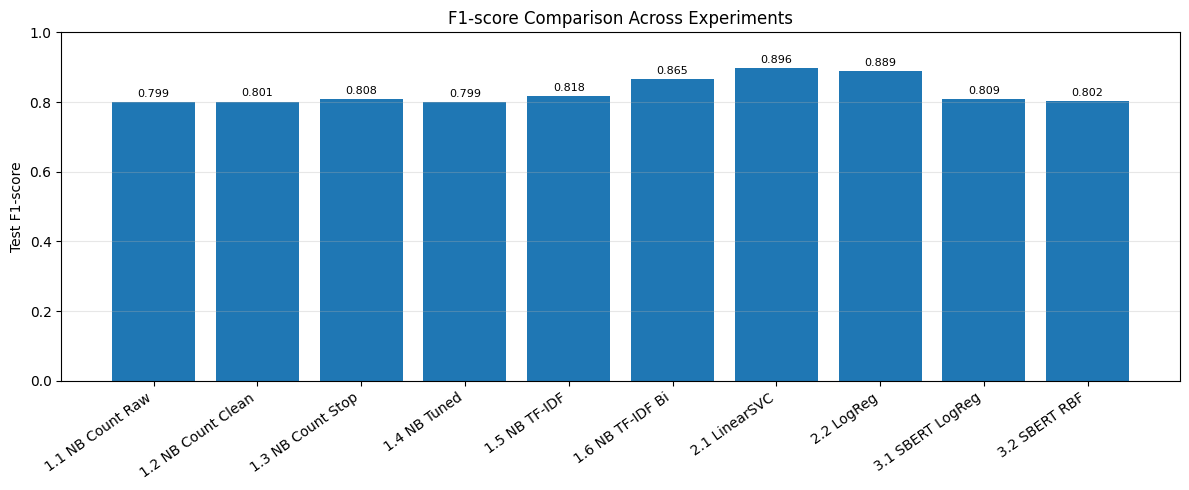

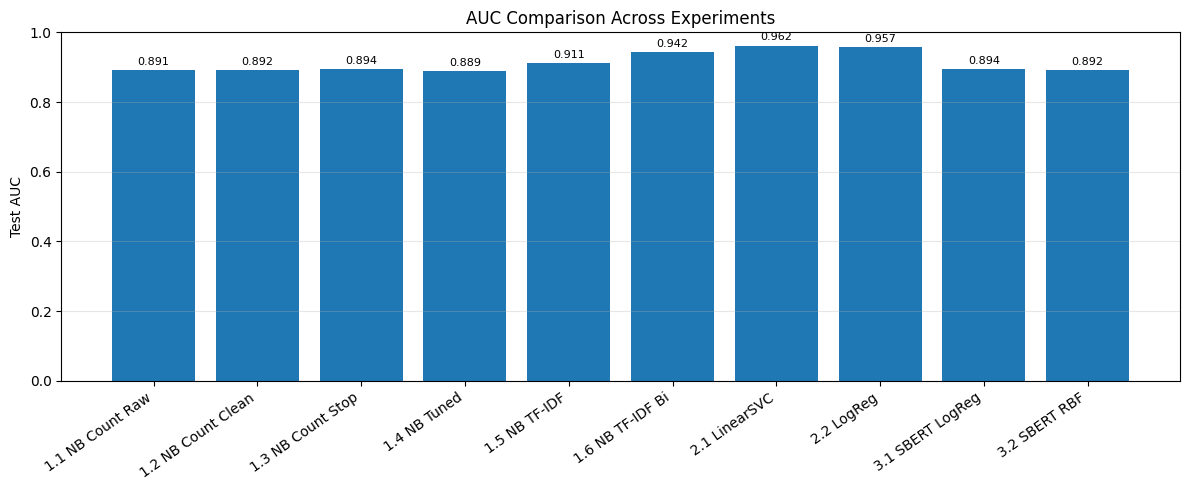

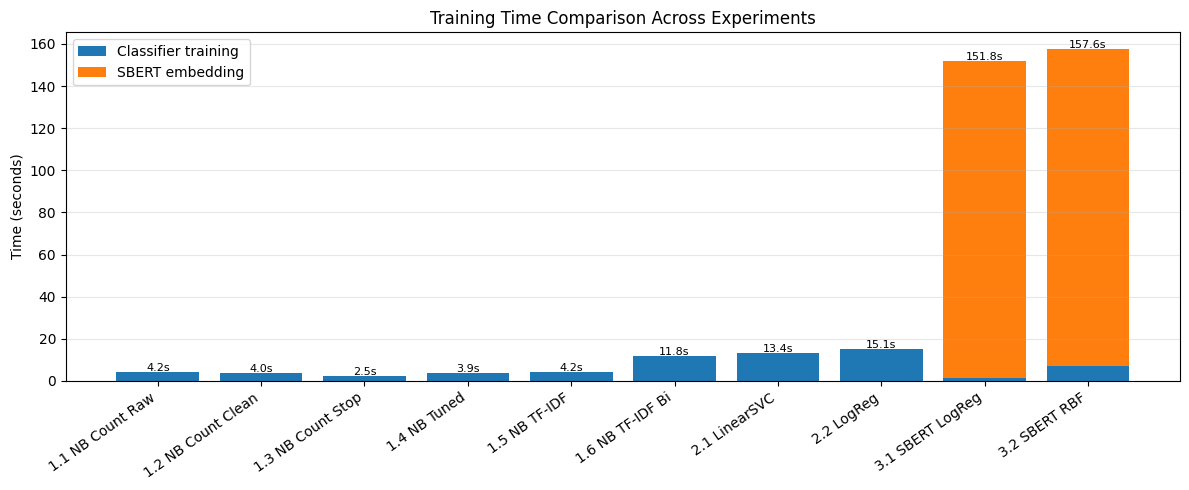

Saved figures to: /content/csci323_outputs


In [12]:
# Step 12: plots

plot_df = result_df.copy()
label_map = {
    "1.1": "1.1 NB Count Raw",
    "1.2": "1.2 NB Count Clean",
    "1.3": "1.3 NB Count Stop",
    "1.4": "1.4 NB Tuned",
    "1.5": "1.5 NB TF-IDF",
    "1.6": "1.6 NB TF-IDF Bi",
    "2.1": "2.1 LinearSVC",
    "2.2": "2.2 LogReg",
    "3.1": "3.1 SBERT LogReg",
    "3.2": "3.2 SBERT RBF"
}
plot_df["name"] = plot_df["exp_id"].map(label_map).fillna(
    plot_df["exp_id"] + " " + plot_df["classifier"]
)

def bar_chart(metric, ylabel, title, filename, ylim_max=1.0):
    plt.figure(figsize=(12, 5))
    bars = plt.bar(plot_df["name"], plot_df[metric])
    plt.xticks(rotation=35, ha="right")
    plt.ylabel(ylabel)
    plt.title(title)
    if ylim_max is not None:
        plt.ylim(0, ylim_max)
    plt.grid(axis="y", alpha=0.3)
    for bar, value in zip(bars, plot_df[metric]):
        if pd.notna(value):
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                min(value + 0.015, 0.98),
                f"{value:.3f}", ha="center", fontsize=8
            )
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=200, bbox_inches="tight")
    plt.show()

bar_chart("test_f1", "Test F1-score",
          "F1-score Comparison Across Experiments",
          "f1_score_comparison.png")

bar_chart("test_auc", "Test AUC",
          "AUC Comparison Across Experiments",
          "auc_comparison.png")

# Training time plot.
# For SBERT, include embedding time too.
plt.figure(figsize=(12, 5))
feat_times = plot_df["feature_time_sec"].fillna(0).values
train_times = plot_df["train_time_sec"].fillna(0).values
bars1 = plt.bar(plot_df["name"], train_times, label="Classifier training")
bars2 = plt.bar(plot_df["name"], feat_times, bottom=train_times, label="SBERT embedding")
plt.xticks(rotation=35, ha="right")
plt.ylabel("Time (seconds)")
plt.title("Training Time Comparison Across Experiments")
plt.legend()
plt.grid(axis="y", alpha=0.3)
for bar, ft, tt in zip(bars1, feat_times, train_times):
    total = ft + tt
    if total > 0:
        plt.text(bar.get_x() + bar.get_width() / 2,
                 total + 0.3, f"{total:.1f}s", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_time_comparison.png"),
            dpi=200, bbox_inches="tight")
plt.show()

print("Saved figures to:", OUTPUT_DIR)

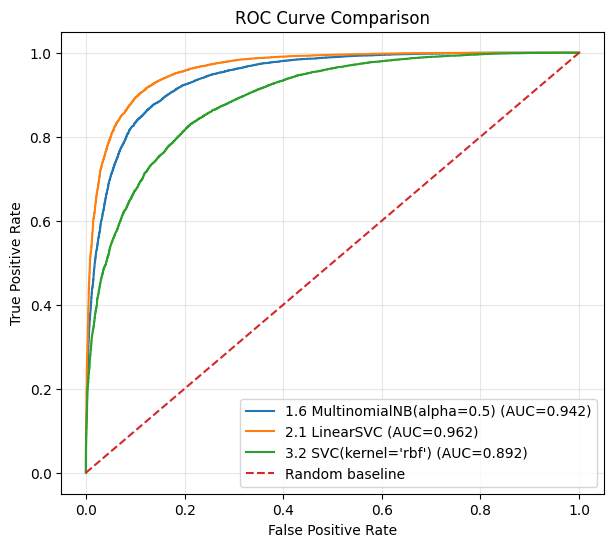

ROC models used: ['1.6', '2.1', '3.2']
Saved: /content/csci323_outputs/roc_curve_comparison.png


In [13]:
# Step 13: ROC curves
# Compare selected models.
# - best Naive Bayes from Tier 1
# - LinearSVC from Tier 2
# - best SBERT model from Tier 3 if available

result_df = pd.DataFrame(results)

best_nb_id = best_tier1_id

roc_ids = [best_nb_id]

if "2.1" in saved_models:
    roc_ids.append("2.1")

tier3_available = result_df[result_df["tier"] == "Tier 3"]
if len(tier3_available) > 0:
    best_sbert_id = tier3_available.sort_values(["val_f1", "val_auc"], ascending=False).iloc[0]["exp_id"]
    roc_ids.append(best_sbert_id)

# Avoid duplicate curves.
roc_ids = list(dict.fromkeys(roc_ids))

plt.figure(figsize=(7, 6))
for exp_id in roc_ids:
    item = saved_models[exp_id]
    score = item["test_score"]
    if score is None:
        continue
    fpr, tpr, _ = roc_curve(item["y_test"], score)
    auc_value = roc_auc_score(item["y_test"], score)
    label = f"{exp_id} {item['row']['classifier']} (AUC={auc_value:.3f})"
    plt.plot(fpr, tpr, label=label)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, "roc_curve_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

print("ROC models used:", roc_ids)
print("Saved:", os.path.join(OUTPUT_DIR, "roc_curve_comparison.png"))

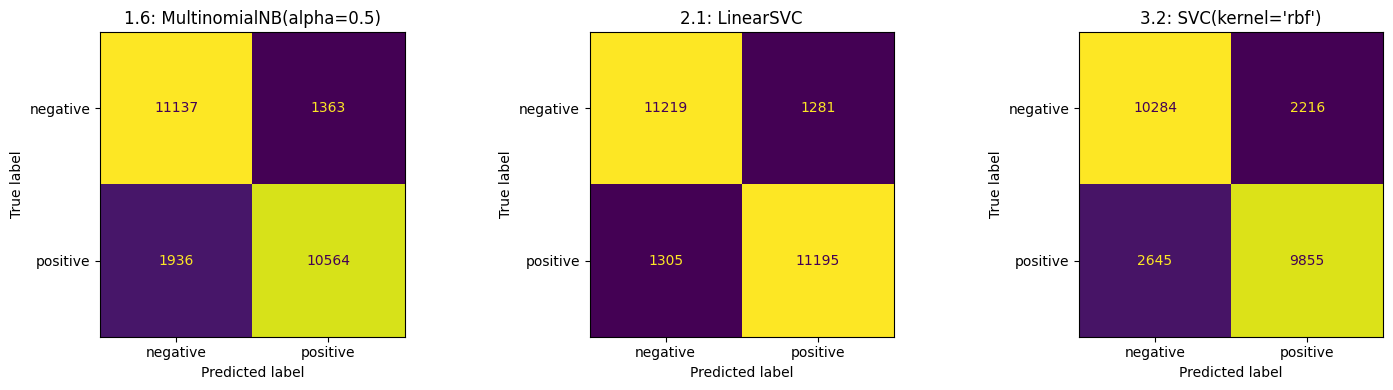

Confusion matrix models used: ['1.6', '2.1', '3.2']
Saved: /content/csci323_outputs/confusion_matrices_selected_models.png


In [14]:
# Step 14: confusion matrices

matrix_ids = []

# Best NB.
matrix_ids.append(best_nb_id)

# SVM.
if "2.1" in saved_models:
    matrix_ids.append("2.1")

# Best SBERT model.
if len(result_df[result_df["tier"] == "Tier 3"]) > 0:
    matrix_ids.append(best_sbert_id)

matrix_ids = list(dict.fromkeys(matrix_ids))

fig, axes = plt.subplots(1, len(matrix_ids), figsize=(5 * len(matrix_ids), 4))
if len(matrix_ids) == 1:
    axes = [axes]

for ax, exp_id in zip(axes, matrix_ids):
    item = saved_models[exp_id]
    cm = confusion_matrix(item["y_test"], item["test_pred"])
    disp = ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"])
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"{exp_id}: {item['row']['classifier']}")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrices_selected_models.png"), dpi=200, bbox_inches="tight")
plt.show()

print("Confusion matrix models used:", matrix_ids)
print("Saved:", os.path.join(OUTPUT_DIR, "confusion_matrices_selected_models.png"))

In [15]:
# Step 15: error analysis
# Look at 10 wrong NB predictions.
# Use confident false positives and false negatives.

NEGATION_PATTERNS = [
    r"\bnot\b", r"n't", r"\bnever\b", r"\bno\b",
    r"\bcannot\b", r"\bcan't\b", r"\bnothing\b", r"\bnobody\b"
]

CONTRAST_PATTERNS = [
    r"\bbut\b", r"\bhowever\b", r"\balthough\b",
    r"\bthough\b", r"\byet\b", r"\bwhile\b", r"\bdespite\b"
]

SARCASM_HINTS = [
    "!", "...", "yeah right", "as if", "supposedly", "so-called",
    '"great"', '"amazing"', '"brilliant"',
    "what a joke", "give me a break"
]

POSITIVE_WORDS = ["love", "great", "amazing", "wonderful", "brilliant",
                  "excellent", "best", "good", "enjoy"]
NEGATIVE_WORDS = ["bad", "boring", "awful", "terrible", "worst",
                  "waste", "hate", "disappointing", "poor"]

def guess_error_type(text):
    """Return a short label describing the likely cause of misclassification."""
    t = " " + str(text).lower() + " "

    has_negation = any(re.search(p, t) for p in NEGATION_PATTERNS)
    has_contrast = any(re.search(p, t) for p in CONTRAST_PATTERNS)
    has_sarcasm = any(s in t for s in SARCASM_HINTS)

    pos_count = sum(t.count(w) for w in POSITIVE_WORDS)
    neg_count = sum(t.count(w) for w in NEGATIVE_WORDS)

    mixed = pos_count >= 2 and neg_count >= 2

    if has_sarcasm and (pos_count > neg_count):
        return "Sarcasm (positive words used ironically)"
    if mixed and has_contrast:
        return "Mixed sentiment with contrast (but/however)"
    if mixed:
        return "Mixed sentiment (both positive and negative words)"
    if has_negation and has_contrast:
        return "Negation with contrast"
    if has_negation:
        return "Negation"
    if len(t.split()) > 400:
        return "Long review, weak signal per word"
    return "Implicit sentiment / hard wording"

best_nb_item = saved_models[best_nb_id]

error_all = pd.DataFrame({
    "review_index": np.arange(len(y_test)),
    "review_text": test_df["text"].values,
    "true_label_id": y_test,
    "predicted_label_id": best_nb_item["test_pred"],
    "score_positive": best_nb_item["test_score"]
})

error_all = error_all[error_all["true_label_id"] != error_all["predicted_label_id"]].copy()
error_all["true_label"] = error_all["true_label_id"].map(label_names)
error_all["predicted_label"] = error_all["predicted_label_id"].map(label_names)
error_all["confidence_wrong"] = (error_all["score_positive"] - 0.5).abs()

# Pick confident mistakes.
false_positive = error_all[
    (error_all["true_label"] == "negative") &
    (error_all["predicted_label"] == "positive")
].sort_values("confidence_wrong", ascending=False)

false_negative = error_all[
    (error_all["true_label"] == "positive") &
    (error_all["predicted_label"] == "negative")
].sort_values("confidence_wrong", ascending=False)

top_fp = false_positive.head(5)
top_fn = false_negative.head(5)

selected_errors = pd.concat([top_fp, top_fn]).reset_index(drop=True)

error_rows = []
for _, row in selected_errors.iterrows():
    review_text = row["review_text"]
    error_rows.append({
        "review_index": int(row["review_index"]),
        "short_review_text": review_text[:600].replace("\n", " ") + "...",
        "true_label": row["true_label"],
        "predicted_label": row["predicted_label"],
        "score_positive": round(float(row["score_positive"]), 4),
        "confidence_wrong": round(float(row["confidence_wrong"]), 4),
        "possible_error_type": guess_error_type(review_text)
    })

error_df = pd.DataFrame(error_rows)
error_path = os.path.join(OUTPUT_DIR, "error_analysis_10_examples.csv")
error_df.to_csv(error_path, index=False)

type_counts = error_df["possible_error_type"].value_counts()
print("Error type breakdown (10 examples from best NB model):")
print(type_counts.to_string())
print()
print("Total wrong predictions for best NB:", len(error_all))
print("False positives:", len(false_positive))
print("False negatives:", len(false_negative))
print()

display(error_df)
print("Saved:", error_path)

Error type breakdown (10 examples from best NB model):
possible_error_type
Negation with contrast                         3
Sarcasm (positive words used ironically)       3
Mixed sentiment with contrast (but/however)    3
Implicit sentiment / hard wording              1

Total wrong predictions for best NB: 3299
False positives: 1363
False negatives: 1936



,review_index,short_review_text,true_label,predicted_label,score_positive,confidence_wrong,possible_error_type
0,6245,Mickey Rourke hunts Diane Lane in Elmore Leona...,negative,positive,0.9587,0.4587,Negation with contrast
1,3624,"Take a few dark and stormy nights, fog coming ...",negative,positive,0.9474,0.4474,Sarcasm (positive words used ironically)
2,4723,I have an affection for these twists on Britis...,negative,positive,0.9375,0.4375,Implicit sentiment / hard wording
3,11053,Julie Delpy stars in this horrific film about ...,negative,positive,0.9333,0.4333,Negation with contrast
4,7613,"I once saw a bit of this film, and was interes...",negative,positive,0.9333,0.4333,Sarcasm (positive words used ironically)
5,15208,**SPOILERS AHEAD**<br /><br />It is really unf...,positive,negative,0.0415,0.4585,Mixed sentiment with contrast (but/however)
6,20409,Forget everything that you have ever read abou...,positive,negative,0.0439,0.4561,Negation with contrast
7,12793,''Meet Sherri..for an evening of Pleasure and ...,positive,negative,0.0492,0.4508,Sarcasm (positive words used ironically)
8,13933,"Un Gatto nel Cervello, or Nightmare Concert as...",positive,negative,0.0510,0.4490,Mixed sentiment with contrast (but/however)
9,17004,This must be the dumbest movie I've ever seen ...,positive,negative,0.0536,0.4464,Mixed sentiment with contrast (but/however)


Saved: /content/csci323_outputs/error_analysis_10_examples.csv


In [16]:
# Step 16: per-class results

per_class_rows = []

for exp_id in matrix_ids:
    item = saved_models[exp_id]
    print("=" * 70)
    print(exp_id, item["row"]["classifier"])
    print(classification_report(item["y_test"], item["test_pred"],
                                target_names=["negative", "positive"]))

    report_dict = classification_report(
        item["y_test"], item["test_pred"],
        target_names=["negative", "positive"], output_dict=True
    )
    for class_name in ["negative", "positive"]:
        per_class_rows.append({
            "exp_id": exp_id,
            "classifier": item["row"]["classifier"],
            "class": class_name,
            "precision": round(report_dict[class_name]["precision"], 4),
            "recall": round(report_dict[class_name]["recall"], 4),
            "f1": round(report_dict[class_name]["f1-score"], 4),
            "support": int(report_dict[class_name]["support"])
        })

per_class_df = pd.DataFrame(per_class_rows)
per_class_path = os.path.join(OUTPUT_DIR, "per_class_metrics.csv")
per_class_df.to_csv(per_class_path, index=False)
display(per_class_df)
print("Saved:", per_class_path)

1.6 MultinomialNB(alpha=0.5)
              precision    recall  f1-score   support

    negative       0.85      0.89      0.87     12500
    positive       0.89      0.85      0.86     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000

2.1 LinearSVC
              precision    recall  f1-score   support

    negative       0.90      0.90      0.90     12500
    positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000

3.2 SVC(kernel='rbf')
              precision    recall  f1-score   support

    negative       0.80      0.82      0.81     12500
    positive       0.82      0.79      0.80     12500

    accuracy                           0.81     25000
   macro avg       0.81      0.81      0.81     25000
weighted 

,exp_id,classifier,class,precision,recall,f1,support
0,1.6,MultinomialNB(alpha=0.5),negative,0.8519,0.8910,0.8710,12500
1,1.6,MultinomialNB(alpha=0.5),positive,0.8857,0.8451,0.8649,12500
2,2.1,LinearSVC,negative,0.8958,0.8975,0.8967,12500
3,2.1,LinearSVC,positive,0.8973,0.8956,0.8965,12500
4,3.2,SVC(kernel='rbf'),negative,0.7954,0.8227,0.8088,12500
5,3.2,SVC(kernel='rbf'),positive,0.8164,0.7884,0.8022,12500


Saved: /content/csci323_outputs/per_class_metrics.csv


In [17]:
# Step 17: notes for discussion
# Choose models using validation F1.

result_df = pd.DataFrame(results)
validation_ranking = result_df.sort_values(["val_f1", "val_auc"], ascending=False).reset_index(drop=True)

best_overall = validation_ranking.iloc[0]
best_nb = result_df[result_df["tier"] == "Tier 1"].sort_values(
    ["val_f1", "val_auc"], ascending=False
).iloc[0]
best_by_test = result_df.sort_values("test_f1", ascending=False).iloc[0]

def fmt(v):
    return f"{v:.4f}" if isinstance(v, float) else str(v)

def lookup(exp_id, col):
    row = result_df[result_df["exp_id"] == exp_id]
    if len(row) == 0:
        return "n/a"
    return fmt(row.iloc[0][col])

notes = [
    {
        "topic": "Validation-selected best model",
        "finding": f"{best_overall['exp_id']} ({best_overall['classifier']}) was selected by validation F1={fmt(best_overall['val_f1'])}. Its final test F1={fmt(best_overall['test_f1'])} and test AUC={fmt(best_overall['test_auc'])}.",
        "evidence_exp_id": best_overall["exp_id"]
    },
    {
        "topic": "Highest test F1 check",
        "finding": f"For checking only, the highest test F1 was {best_by_test['exp_id']} ({best_by_test['classifier']}) with test F1={fmt(best_by_test['test_f1'])}. The report should still say models were chosen by validation F1.",
        "evidence_exp_id": best_by_test["exp_id"]
    },
    {
        "topic": "Best Naive Bayes model",
        "finding": f"{best_nb['exp_id']} was the best NB setup by validation F1={fmt(best_nb['val_f1'])}; its final test F1={fmt(best_nb['test_f1'])}.",
        "evidence_exp_id": best_nb["exp_id"]
    },
    {
        "topic": "Impact of basic preprocessing",
        "finding": f"Raw text test F1={lookup('1.1', 'test_f1')} vs cleaned text test F1={lookup('1.2', 'test_f1')}. Basic cleaning had only a small effect because BoW still sees similar key words.",
        "evidence_exp_id": "1.1 vs 1.2"
    },
    {
        "topic": "Impact of stopword removal",
        "finding": f"With stopword removal test F1={lookup('1.3', 'test_f1')} vs cleaned text test F1={lookup('1.2', 'test_f1')}. This checks whether common words add noise for NB.",
        "evidence_exp_id": "1.2 vs 1.3"
    },
    {
        "topic": "Laplace smoothing alpha",
        "finding": "Alpha was tuned on the validation set. The alpha_tuning_curve.png file shows which alpha gave the best validation F1.",
        "evidence_exp_id": "1.4"
    },
    {
        "topic": "BoW vs TF-IDF",
        "finding": f"BoW test F1={lookup('1.2', 'test_f1')} vs TF-IDF test F1={lookup('1.5', 'test_f1')}. TF-IDF can help because it reduces the weight of very common words.",
        "evidence_exp_id": "1.2 vs 1.5"
    },
    {
        "topic": "Unigram vs bigram TF-IDF",
        "finding": f"Unigram test F1={lookup('1.5', 'test_f1')} vs unigram+bigram test F1={lookup('1.6', 'test_f1')}. Bigrams can capture short phrases such as 'not good'.",
        "evidence_exp_id": "1.5 vs 1.6"
    },
    {
        "topic": "Traditional classifiers",
        "finding": f"Best NB test F1={lookup(best_nb['exp_id'], 'test_f1')}, LinearSVC test F1={lookup('2.1', 'test_f1')}, and Logistic Regression test F1={lookup('2.2', 'test_f1')}. This compares generative and discriminative classifiers using the same feature setting.",
        "evidence_exp_id": f"{best_nb['exp_id']} vs 2.1 vs 2.2"
    },
    {
        "topic": "SBERT sentence embeddings",
        "finding": f"SBERT+LR test F1={lookup('3.1', 'test_f1')} and SBERT+RBF SVC test F1={lookup('3.2', 'test_f1')}. SBERT is more modern, but it may not beat TF-IDF on long IMDb reviews without fine-tuning.",
        "evidence_exp_id": "3.1, 3.2"
    },
    {
        "topic": "Runtime trade-off",
        "finding": "NB is fastest; LinearSVC and Logistic Regression take longer; SBERT needs an embedding step before classification. The training_time_comparison.png chart supports this point.",
        "evidence_exp_id": "training_time_comparison.png"
    },
    {
        "topic": "Common error patterns",
        "finding": "The error-analysis table checks difficult wrong predictions, including negation, mixed sentiment, sarcasm, and implicit sentiment.",
        "evidence_exp_id": "error_analysis_10_examples.csv"
    }
]

discussion_df = pd.DataFrame(notes)
discussion_path = os.path.join(OUTPUT_DIR, "discussion_notes.csv")
discussion_df.to_csv(discussion_path, index=False)
display(discussion_df)
print("Saved:", discussion_path)

print()
print("Key result notes")
print("------------------------------------")
for row in notes:
    print(f"- [{row['topic']}] {row['finding']}")

,topic,finding,evidence_exp_id
0,Validation-selected best model,2.1 (LinearSVC) was selected by validation F1=...,2.1
1,Highest test F1 check,"For checking only, the highest test F1 was 2.1...",2.1
2,Best Naive Bayes model,1.6 was the best NB setup by validation F1=0.8...,1.6
3,Impact of basic preprocessing,Raw text test F1=0.7990 vs cleaned text test F...,1.1 vs 1.2
4,Impact of stopword removal,With stopword removal test F1=0.8083 vs cleane...,1.2 vs 1.3
5,Laplace smoothing alpha,Alpha was tuned on the validation set. The alp...,1.4
6,BoW vs TF-IDF,BoW test F1=0.8009 vs TF-IDF test F1=0.8176. T...,1.2 vs 1.5
7,Unigram vs bigram TF-IDF,Unigram test F1=0.8176 vs unigram+bigram test ...,1.5 vs 1.6
8,Traditional classifiers,"Best NB test F1=0.8649, LinearSVC test F1=0.89...",1.6 vs 2.1 vs 2.2
9,SBERT sentence embeddings,SBERT+LR test F1=0.8095 and SBERT+RBF SVC test...,"3.1, 3.2"


Saved: /content/csci323_outputs/discussion_notes.csv

Key result notes
------------------------------------
- [Validation-selected best model] 2.1 (LinearSVC) was selected by validation F1=0.9065. Its final test F1=0.8965 and test AUC=0.9619.
- [Highest test F1 check] For checking only, the highest test F1 was 2.1 (LinearSVC) with test F1=0.8965. The report should still say models were chosen by validation F1.
- [Best Naive Bayes model] 1.6 was the best NB setup by validation F1=0.8761; its final test F1=0.8649.
- [Impact of basic preprocessing] Raw text test F1=0.7990 vs cleaned text test F1=0.8009. Basic cleaning had only a small effect because BoW still sees similar key words.
- [Impact of stopword removal] With stopword removal test F1=0.8083 vs cleaned text test F1=0.8009. This checks whether common words add noise for NB.
- [Laplace smoothing alpha] Alpha was tuned on the validation set. The alpha_tuning_curve.png file shows which alpha gave the best validation F1.
- [BoW vs TF-I

## Output files

After running all cells, use these files from `/content/csci323_outputs` for the report:

- `dataset_summary.csv`
- `experiment_design.csv`
- `alpha_tuning_results.csv`
- `final_result_table.csv`
- `all_experiment_results_ranked_by_validation.csv`
- `error_analysis_10_examples.csv`
- `per_class_metrics.csv`
- `discussion_notes.csv`
- `alpha_tuning_curve.png`
- `f1_score_comparison.png`
- `auc_comparison.png`
- `roc_curve_comparison.png`
- `confusion_matrices_selected_models.png`
- `training_time_comparison.png`

In [18]:
# Step 19: zip and download output files
# Run this after all experiment cells finish.

import os
import glob
import shutil
from google.colab import files

output_dir = OUTPUT_DIR if "OUTPUT_DIR" in globals() else "/content/csci323_outputs"

if not os.path.exists(output_dir):
    print("Output folder not found:", output_dir)
    print("Please run the notebook from Step 1 to the end first.")
else:
    output_files = sorted(glob.glob(os.path.join(output_dir, "*")))
    print("Output folder:", output_dir)
    print("Number of files found:", len(output_files))
    for path in output_files:
        print("-", os.path.basename(path))

    zip_base = "/content/csci323_outputs"
    zip_path = zip_base + ".zip"
    if os.path.exists(zip_path):
        os.remove(zip_path)

    shutil.make_archive(zip_base, "zip", output_dir)
    print("Created zip file:", zip_path)
    files.download(zip_path)

Output folder: /content/csci323_outputs
Number of files found: 18
- all_experiment_results_ranked_by_test.csv
- all_experiment_results_ranked_by_validation.csv
- alpha_tuning_curve.png
- alpha_tuning_results.csv
- auc_comparison.png
- confusion_matrices_selected_models.png
- dataset_summary.csv
- discussion_notes.csv
- error_analysis_10_examples.csv
- experiment_design.csv
- f1_score_comparison.png
- final_result_table.csv
- per_class_metrics.csv
- roc_curve_comparison.png
- sbert_test.npy
- sbert_train.npy
- sbert_val.npy
- training_time_comparison.png
Created zip file: /content/csci323_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>